<a href="https://colab.research.google.com/github/nunestataferreira-create/Aula_Git/blob/main/Desafio2_Estatistica_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ---------- Bibliotecas: ferramentas prontas que o Python usa ----------
import warnings                    # esconde avisos técnicos para não distrair
from pathlib import Path           # manipula caminhos de arquivos e pastas
import shutil                      # manipula arquivos e pastas (ex.: mover, copiar, apagar)

# Estas linhas servem para trabalhar no Google Colab (conectar ao Drive e enviar arquivos)
from google.colab import drive     # conecta o Google Drive ao Colab (para ler e salvar arquivos)
from google.colab import files     # (files) envia arquivos do seu computador para o Colab

# Bibliotecas de análise de dados e de gráficos
import pandas as pd                # tabelas de dados (DataFrame)
import seaborn as sns              # gráficos bonitos e simples
import matplotlib.pyplot as plt    # ajustes nos gráficos (título, linhas...)

# ---------- Configurações gerais (valem para todos os gráficos abaixo) ----------
warnings.filterwarnings("ignore")           # esconde avisos técnicos para não distrair
sns.set_theme(style="whitegrid")            # deixa todos os gráficos com um visual limpo
plt.rcParams["figure.figsize"] = (8, 6)    # tamanho padrão dos gráficos (largura, altura)

Carregar os dados

In [3]:
# Nomes das tabelas do seu tema (veja a tabela acima), iguais aos nomes dos arquivos CSV.
NOME_TABELA_DIMENSAO = "pacientes"   # ex.: "livros"
NOME_TABELA_FATO = "atendimentos"           # ex.: "emprestimos"

# ---------- 1) Conectando ao Google Drive ----------
drive.mount("/content/drive")      # vai pedir autorização na primeira vez

# ---------- 2) Dizendo onde os arquivos estão guardados ----------
pasta_dados = Path("/content/drive/MyDrive/Colab Notebooks/desafios/dados")   # pasta onde a base fica guardada no Drive
pasta_dados.mkdir(parents=True, exist_ok=True)                                # cria a pasta "dados" se faltar

# O "/" junta a pasta com o nome do arquivo (o nome vem da variável de cada tabela).
caminho_dimensao = pasta_dados / f"{NOME_TABELA_DIMENSAO}.csv"
caminho_fato = pasta_dados / f"{NOME_TABELA_FATO}.csv"

# ---------- 3) Se faltar algum arquivo, envia os dois de uma vez e o código separa ----------
if not caminho_dimensao.exists() or not caminho_fato.exists():
    print(f"Selecione os arquivos CSV ({NOME_TABELA_DIMENSAO} e {NOME_TABELA_FATO}). Pode escolher os dois de uma vez:")
    enviados = files.upload()                                  # abre o seletor; aceita vários arquivos

    for nome_enviado in enviados:                              # percorre cada arquivo enviado
        if NOME_TABELA_DIMENSAO in nome_enviado.lower():       # o nome contém o da dimensão? salva como dimensão
            shutil.move(nome_enviado, caminho_dimensao)        # salva já com o nome da tabela
            print(f"{nome_enviado} -> {caminho_dimensao.name}")
        elif NOME_TABELA_FATO in nome_enviado.lower():         # o nome contém o da fato? salva como fato
            shutil.move(nome_enviado, caminho_fato)
            print(f"{nome_enviado} -> {caminho_fato.name}")
        else:                                                  # nome que não combina com nenhuma tabela
            print(f"Ignorado: {nome_enviado} (o nome não contém '{NOME_TABELA_DIMENSAO}' nem '{NOME_TABELA_FATO}')")

# Confere se os dois arquivos estão no Drive antes de ler.
for caminho in [caminho_dimensao, caminho_fato]:
    if not caminho.exists():
        raise FileNotFoundError(f"Falta o arquivo {caminho.name}. Execute a célula de novo e envie-o.")

# ---------- 4) Lendo os dois arquivos ----------
df_dimensao = pd.read_csv(caminho_dimensao)
df_fato = pd.read_csv(caminho_fato)

print(NOME_TABELA_DIMENSAO, "->", len(df_dimensao), "linhas")
print(NOME_TABELA_FATO, "->", len(df_fato), "linhas")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Selecione os arquivos CSV (pacientes e atendimentos). Pode escolher os dois de uma vez:


Saving pacientes.csv to pacientes.csv
Saving atendimentos.csv to atendimentos.csv
pacientes.csv -> pacientes.csv
atendimentos.csv -> atendimentos.csv
pacientes -> 10500 linhas
atendimentos -> 42000 linhas


Célula 03 · Conhecendo a tabela dimensão

In [4]:
# Quantas linhas (registros do cadastro) e colunas (variáveis) tem a tabela dimensão?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_dimensao.shape
print(f"A tabela dimensão tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_dimensao.head())

A tabela dimensão tem 10500 linhas e 6 colunas (variáveis)


,paciente_id,nome,data_nascimento,sexo,bairro,tipo_convenio
0,1,Juan Lopes,1983-12-08,M,Vila Madre Gertrudes 1ª Seção,SUS
1,2,Rafael Abreu,2017-06-21,outro,Vila Antena,SUS
2,3,Dra. Julia Montenegro,1989-01-28,M,São Francisco Das Chagas,SUS
3,4,Thiago Caldeira,1936-02-02,M,Santo Antônio,SUS
4,5,Letícia Porto,1994-08-19,F,Vila Tirol,SUS


Célula 04 · Conhecendo a tabela fato

In [5]:
# Quantas linhas (eventos) e colunas (variáveis) tem a tabela fato?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_fato.shape
print(f"A tabela fato tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_fato.head())

A tabela fato tem 42000 linhas e 8 colunas (variáveis)


,atendimento_id,paciente_id,data_hora_chegada,sintoma_principal,nivel_triagem,tempo_espera_min,profissional_responsavel,desfecho
0,1,9633,2025-01-18 21:49:41,falta de ar,verde,37,Enfermeira 19,internado
1,2,2676,2025-04-27 08:55:07,falta de ar,amarelo,28,Enfermeiro 10,alta
2,3,4503,2026-07-08 06:54:14,vômito/náusea,amarelo,20,Enfermeiro 21,alta
3,4,7532,2026-05-04 12:21:15,tontura,verde,87,Tecnico Enfermagem 12,alta
4,5,2728,2025-07-12 08:48:22,dor de cabeça,verde,39,Tecnico Enfermagem 06,alta


Passo 4 — Checar a base antes de calcular

Célula 05 · Tipos das colunas


In [6]:
# 1) Tipo de cada coluna e quantidade de valores preenchidos. Compare com o esquema do plano do tema.
df_fato.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42000 entries, 0 to 41999
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   atendimento_id            42000 non-null  int64 
 1   paciente_id               42000 non-null  int64 
 2   data_hora_chegada         42000 non-null  object
 3   sintoma_principal         42000 non-null  object
 4   nivel_triagem             42000 non-null  object
 5   tempo_espera_min          42000 non-null  int64 
 6   profissional_responsavel  42000 non-null  object
 7   desfecho                  42000 non-null  object
dtypes: int64(3), object(5)
memory usage: 2.6+ MB


Célula 06 · Valores ausentes

In [7]:
# 2) Valores ausentes por coluna (tabela fato).
print("\nValores ausentes por coluna:")
print(df_fato.isna().sum())


Valores ausentes por coluna:
atendimento_id              0
paciente_id                 0
data_hora_chegada           0
sintoma_principal           0
nivel_triagem               0
tempo_espera_min            0
profissional_responsavel    0
desfecho                    0
dtype: int64


Célula 07 · Linhas duplicadas

In [8]:
# 3) Linhas duplicadas (tabela fato).
print("\nLinhas duplicadas:", df_fato.duplicated().sum())


Linhas duplicadas: 0


Célula 08 · Chave estrangeira

In [24]:
# 4) Chave estrangeira: todos os registros da tabela fato devem apontar para um ID que existe na tabela dimensão.
COLUNA_FK = "paciente_id"        # ex.: "livro_id" (coluna da fato que referencia a dimensão)
COLUNA_ID = "paciente_id"   # ex.: "livro_id" (coluna de ID da dimensão)
print("\nChaves estrangeiras que batem:", df_fato[COLUNA_FK].isin(df_dimensao[COLUNA_ID]).all())


Chaves estrangeiras que batem: True


Célula 09 · Checar a coluna numérica

In [25]:
# Coluna numérica escolhida no Passo 1 (nome EXATO, como está no esquema do tema).
COLUNA_NUMERICA = "tempo_espera_min"

# A coluna escolhida, como uma série (uma coluna do DataFrame).
serie_numerica = df_fato[COLUNA_NUMERICA]
print("Valores preenchidos:", serie_numerica.count(), "| ausentes:", serie_numerica.isna().sum())

Valores preenchidos: 42000 | ausentes: 0


Célula 10 · Medidas estatísticas

In [30]:
# Média muito diferente da mediana é sinal de valores extremos ou de dados assimétricos.
print("Média - mediana:", round(medidas["Média"] - medidas["Mediana"], 2))

# Converte de minutos para horas
serie_horas = serie_numerica / 60

# Medidas de Tendência central e dispersão.
medidas = pd.Series({
    "Média": serie_horas.mean(),
    "Mediana": serie_horas.median(),
    "Moda": serie_horas.mode()[0],          # se houver empate, a primeira será selecionada
    "Desvio padrão": serie_horas.std(),
    "Variância": serie_horas.var(),
    "Mínimo": serie_horas.min(),
    "Máximo": serie_horas.max(),
    "Amplitude": serie_horas.max() - serie_horas.min(),
}).round(2)

# Exibe com a unidade "horas" (ou "h") na frente de cada número
display(medidas.astype(str) + " h")

# Média muito diferente da mediana é sinal de valores extremos ou de dados assimétricos.
print("Média - mediana:", round(medidas["Média"] - medidas["Mediana"], 2), "horas")

Média - mediana: 12.4


,0
Média,1.06 h
Mediana,0.85 h
Moda,0.0 h
Desvio padrão,0.86 h
Variância,0.74 h
Mínimo,0.0 h
Máximo,5.97 h
Amplitude,5.97 h


Média - mediana: 0.21 horas


Passo 6 — Escrever as frases de insight

A média de tempo_espera_min é 1.06 h: dentro dos parâmetros de espera

A mediana de tempo_espera_min é 0.85 h: O tempo de espera está abaixo da media, 17 min abaixo

Desvio padrão: O desvio padrão é praticamente igual à mediana e representa mais de 80% do valor da média. Isso demonstra alta imprevisibilidade no fluxo: um paciente pode ser atendido imediatamente ou esperar quase duas horas dentro de apenas um desvio padrão ($63,40 + 51,79 = 115,19$ min)

Decisão final: como a mediana (0,85 h) representa melhor o atendimento típico do que a média, e a variação é alta, o foco deve ser investigar e reduzir os atendimentos muito longos e padronizar o processo, antes de definir uma meta de tempo. Também é preciso verificar os registros com 0,0 h, que podem ser dados não preenchidos e distorcer as medidas.

Célula 11 · Juntar a fato com a dimensão

In [32]:
# Junta a fato com a dimensão: cada registro da fato recebe as colunas do seu cadastro.
df_completo = df_fato.merge(df_dimensao, left_on=COLUNA_FK, right_on=COLUNA_ID, how="left", suffixes=("", "_dim"))

print("Linhas da fato:", len(df_fato), "| depois da junção:", len(df_completo))   # precisam ser iguais

Linhas da fato: 42000 | depois da junção: 42000


Célula 12 · Comparar grupos por uma coluna da fato

In [35]:
# Coluna categórica usada para comparar (da fato ou da dimensão). Poucos valores diferentes funcionam melhor.
COLUNA_GRUPO = "nivel_triagem"

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,std
nivel_triagem,,,,
azul,6349,149.47,150.0,57.38
verde,16934,69.62,69.0,29.34
amarelo,14631,34.64,34.0,16.78
laranja,3318,8.06,7.0,6.70
vermelho,768,1.73,0.0,2.66



Leitura da comparação

Grupo com a maior média e se a mediana confirma:
• O grupo azul tem a maior média (149,47) e a mediana confirma isso totalmente (150,0).
• Quando a média e a mediana estão coladas assim (149,47 vs. 150), significa que os dados são bem simétricos. Não são apenas alguns casos isolados que esperam cerca de 2 horas e meia; esse é o comportamento padrão e real desse grupo. O mesmo acontece nos grupos verde (69,6 vs. 69) e amarelo (34,6 vs. 34).

Grupo com o maior desvio padrão: valores mais espalhados:
O grupo azul tem o maior desvio padrão (57,38).
• O desvio padrão mede a "bagunça" ou a imprevisibilidade. Como os pacientes azuis não têm urgência, o tempo de espera deles varia muito: se o hospital estiver vazio, eles são atendidos rápido; se chegar uma emergência (vermelho/laranja), eles vão para o fim da fila e esperam muito mais. Já no grupo vermelho (std de 2,66), o tempo é super previsível e travado perto do zero.

Se os grupos têm médias parecidas, o que isso diz sobre a categoria:
• Isso indicaria que a variável nivel_triagem não tem poder de separação (ou que o hospital está falhando na triagem).
• Quando você agrupa por uma categoria e as médias dão quase iguais, significa que essa categoria não explica o comportamento da variável numérica. No mundo real desse hospital, se todas as cores tivessem média de 60 minutos, significaria que um paciente infartando (vermelho) estaria esperando o mesmo tempo que alguém com um resfriado leve (azul) — ou seja, o sistema de priorização não estaria funcionando na prática.

Célula 13 · Comparar grupos por uma coluna da dimensão

In [36]:
COLUNA_GRUPO = "tipo_convenio"     # coluna da dimensão: só existe em df_completo por causa da junção

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,std
tipo_convenio,,,,
convenio,8259,64.24,52.0,52.21
particular,4851,63.70,51.0,51.80
SUS,28890,63.11,51.0,51.66


Conclusão principal: os grupos são quase iguais
A diferença entre a maior e a menor média é de cerca de 1,1 minuto (64,24 contra 63,11), ou seja, menos de 2%.
Essa diferença é minúscula perto do desvio padrão de cerca de 52 min. Dentro de cada grupo, os tempos variam quase 50 vezes mais do que a diferença entre os grupos.
As medianas diferem em apenas 1 minuto.

Como você mesmo observou, médias quase iguais também são um resultado: o tipo de convênio não explica a variação no tempo de atendimento. Convênio, particular e SUS são atendidos praticamente no mesmo tempo.

Célula 14 · Regra do IQR

In [37]:
# Faixa central dos dados: do 1º ao 3º quartil (25% e 75%).
q1 = serie_numerica.quantile(0.25)
q3 = serie_numerica.quantile(0.75)
iqr = q3 - q1

# Regra usual: fora de [Q1 - 1,5 x IQR ; Q3 + 1,5 x IQR] é candidato a outlier.
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# Cálculo do número de outliers
sem_outliers = serie_numerica[(serie_numerica >= limite_inferior) & (serie_numerica <= limite_superior)]
qtd_outliers = serie_numerica.count() - sem_outliers.count()

print(f"Limites: {limite_inferior:.2f} a {limite_superior:.2f}")
print(f"Outliers: {qtd_outliers} de {serie_numerica.count()} valores")
print("Maiores valores:", serie_numerica.nlargest(5).tolist())
print("Menores valores:", serie_numerica.nsmallest(5).tolist())

Limites: -59.00 a 173.00
Outliers: 2161 de 42000 valores
Maiores valores: [358, 346, 342, 341, 330]
Menores valores: [0, 0, 0, 0, 0]


Célula 15 · Medidas com e sem os candidatos a outlier

In [38]:
# Compara as medidas com e sem os candidatos a outlier.
comparacao = pd.DataFrame({
    "Com outliers": [serie_numerica.mean(), serie_numerica.median(), serie_numerica.std()],
    "Sem outliers": [sem_outliers.mean(), sem_outliers.median(), sem_outliers.std()],
}, index=["Média", "Mediana", "Desvio padrão"]).round(2)
display(comparacao)

,Com outliers,Sem outliers
Média,63.40,55.38
Mediana,51.00,48.00
Desvio padrão,51.79,39.09


Decisão: manter os candidatos a outlier.
Ao removê-los, a média caiu de 63,40 para 55,38 min (−12,6%), o desvio padrão de 51,79 para 39,09 (−24,5%) e a mediana apenas de 51,00 para 48,00 (−5,9%), o que confirma que os valores extremos puxam a média e a dispersão. Porém, atendimentos longos são plausíveis no contexto clínico (procedimentos complexos ou intercorrências) e representam casos reais. Por isso, foram mantidos e a mediana foi adotada como medida de referência do atendimento típico. Os registros com 0 min serão verificados à parte, pois podem indicar dados não preenchidos

**Leitura e decisão registrada**

Outliers pelo IQR: a regra marcou [N] valores de 42.000 registros ([X]%), a partir de [limite superior] min. Sem eles, a média cai de 63,40 para 55,38 min (−12,6%), o desvio padrão de 51,79 para 39,09 (−24,5%) e a mediana apenas de 51,00 para 48,00 (−5,9%). A média e a dispersão são puxadas pelos valores extremos, enquanto a mediana é bem mais estável.

Decisão: manter. Atendimentos longos são plausíveis no contexto clínico (procedimentos complexos, intercorrências) e representam casos reais, não erros de preenchimento. Como a distribuição é assimétrica, o IQR tende a marcar como “outlier” parte legítima da cauda longa. A mediana foi adotada como medida de referência do atendimento típico.

Valores ausentes: [X] registros sem valor na coluna de tempo. [Preencha: excluídos da análise / mantidos como NaN / tratados], porque [motivo]. Os registros com 0 min foram verificados à parte, pois podem ser dados não preenchidos e não casos reais.

Célula 16 · Assimetria (skew)

In [39]:
# Assimetria: perto de 0 = formato equilibrado; positiva = cauda para valores altos; negativa = para valores baixos.
print("Assimetria:", round(serie_numerica.skew(), 2))

Assimetria: 1.42


Célula 17 · Percentis

In [ ]:
# Percentis: por exemplo, 50% dos valores ficam na mediana ou abaixo dela.
print(serie_numerica.quantile([0.10, 0.25, 0.50, 0.75, 0.90]))

Célula 18 · Quantidade de valores por faixa

In [40]:
# Quantidade de valores em 5 faixas de mesmo tamanho (a versão em texto de um histograma).
display(pd.cut(serie_numerica, bins=5).value_counts().sort_index())

,count
tempo_espera_min,
"(-0.358, 71.6]",28024
"(71.6, 143.2]",10409
"(143.2, 214.8]",2775
"(214.8, 286.4]",741
"(286.4, 358.0]",51


Assimetria: a contagem cai de forma contínua da primeira à última faixa, o que mostra uma assimetria positiva (à direita), com cauda longa. Isso é coerente com a média (63,40) maior que a mediana (51,00). O valor numérico exato da assimetria eu não tenho, pois ele sai de serie_numerica.skew(). Quanto mais acima de 0, mais pesada é a cauda.

Percentis: como a primeira faixa acumula 66,7% e as duas primeiras 91,5%, tanto os 75% quanto os 90% dos registros ficam entre 71,6 e 143,2 min. Em particular, 90% dos registros esperam no máximo cerca de 143 min. Os valores exatos saem de serie_numerica.quantile([0.75, 0.90]).
Primeira faixa e faixas altas: 28.024 registros (66,7%) estão na primeira faixa. Nas três últimas faixas (acima de 143,2 min) ficam 3.567 registros (8,5%), e nas duas mais altas (acima de 214,8 min) apenas 792 (1,9%).

Em palavras: a maioria dos pacientes espera entre 0 e cerca de 72 minutos, cerca de 9 em cada 10 esperam até cerca de 143 minutos, e poucos passam de 215 minutos (3h35). O máximo é de 358 min (5h58).

Passo 10 — Redigir a recomendação de decisão

**Pergunta de negócio:** O tempo de espera é alto no posto ? ou varia pelo nível de triagem?

Evidência 1: A média de 63,40 min é maior que a mediana de 51,00 min (cerca de 12 min de diferença). Isso significa que a distribuição do tempo de espera é assimétrica à direita: a maioria dos pacientes espera pouco, e alguns casos longos, de até 358 min, puxam a média para cima. Por isso, a mediana representa melhor a espera típica.

Quase todo mundo é atendido rápido, mas poucos esperam horas, e esses casos puxam a média para cima

Célula 19 · Histograma

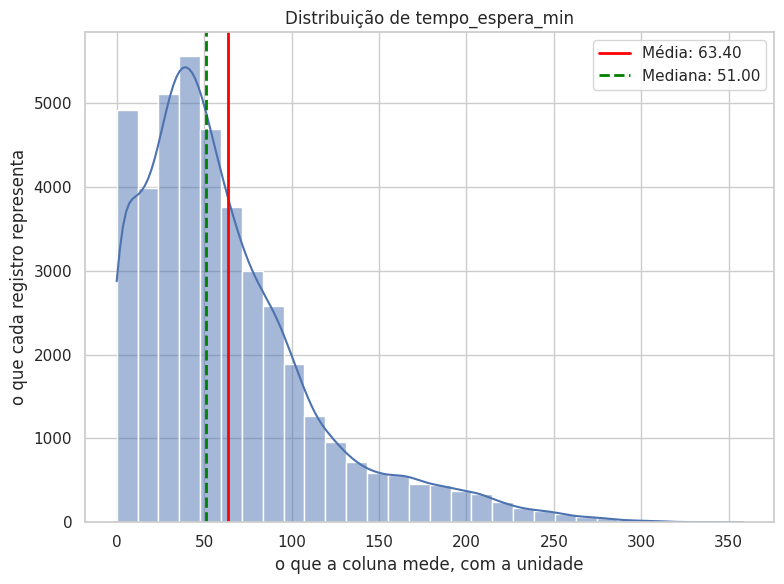

In [42]:
# Histograma: como os valores se distribuem, com a curva da distribuição e as linhas de média e mediana.
sns.histplot(serie_numerica.dropna(), bins=30, kde=True)
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.axvline(serie_numerica.median(), color="green", linestyle="--", linewidth=2, label=f"Mediana: {serie_numerica.median():.2f}")
plt.title(f"Distribuição de {COLUNA_NUMERICA}")
plt.xlabel("o que a coluna mede, com a unidade")        # lacuna: nome do eixo x, em linguagem simples
plt.ylabel("o que cada registro representa")            # lacuna: nome do eixo y, em linguagem simples
plt.legend()
plt.tight_layout()
plt.show()

Célula 20 · Boxplot

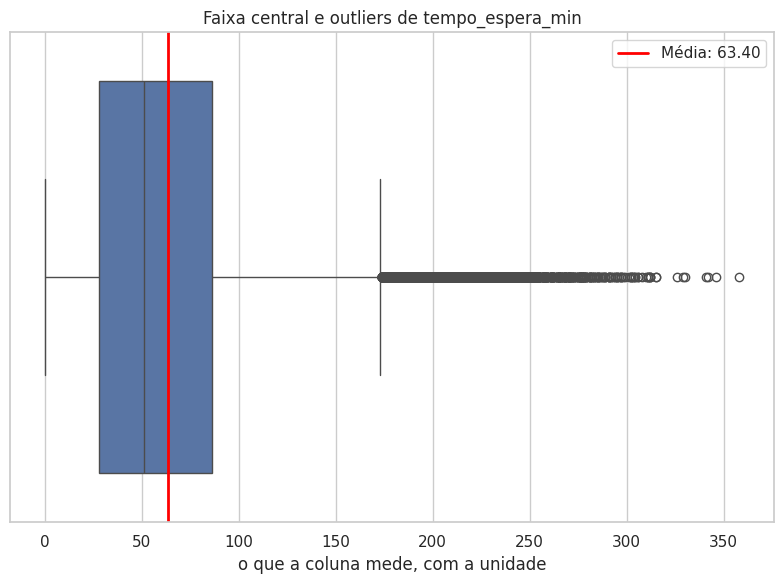

In [43]:
# Boxplot: a caixa é a faixa central (25% a 75%); os pontos fora são candidatos a outlier.
sns.boxplot(x=serie_numerica.dropna())
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.title(f"Faixa central e outliers de {COLUNA_NUMERICA}")
plt.xlabel("o que a coluna mede, com a unidade")        # lacuna: nome do eixo x, em linguagem simples
plt.legend()
plt.tight_layout()
plt.show()

Registrar o uso de IA

# Generated-by: AI (Claude)